# 🧪 Proyecto **Centinela** · Fase 1 — Línea base con MLP (panel nacional)
### Redes Neuronales — Deep Learning · Maestría en Ciencia de Datos · Universidad Santo Tomás

[![Abrir en Colab (opcional)](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/JuSeUlloa/Hurto-Personas-Centinela/blob/main/02_scaffold_centinela_fase1.ipynb) 

Este cuaderno entrega la **línea base tabular con MLP** de la Fase 1 del Proyecto Integrador *Centinela* sobre **datos reales**: la API del panel del proyecto (`/api/dbx/bronze`, reporte de hurto a personas de la Policía Nacional/DIJIN · SIEDCO, CC BY-SA 4.0) y la población (`/api/dbx/gold`, `pob_dane_2025`, DANE) como denominador de la tasa.

---
**Contenido**
0. Preparación del entorno
1. Carga de datos reales (panel nacional) y partición cronológica
2. Exploración de datos reales (EDA)
3. Arquitectura del MLP (≥ 2 capas ocultas)
4. Pérdida, optimizador y bucle de entrenamiento (50 épocas)
5. Funciones de diagnóstico + **ablación de features de calendario**
6. Inducir y corregir el sobreajuste con *Dropout*
7. Líneas base comprometidas (Propuesta de Datos §6)
8. Cierre · entregables


## 0. Preparación del entorno

Se importan las librerías de soporte (`numpy`, `matplotlib`, `sklearn`) y se fija una **semilla** para reproducibilidad. PyTorch se importa en la Sección 3, donde se define el modelo (`urllib`/`hashlib`/`time`, de la librería estándar, entran con la celda de datos).


In [34]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
import json, urllib.request, hashlib, time
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix, precision_score, recall_score

SEMILLA = 42
np.random.seed(SEMILLA)

USTA_MORADO, USTA_ROSA, USTA_NAVY = "#3D008D", "#ED1E79", "#001A4D"
plt.rcParams.update({"figure.dpi": 110, "font.size": 11, "axes.grid": True, "grid.alpha": 0.3})

def miles(n):
    return f"{n:,}".replace(",", ".")

print("Entorno de soporte listo · numpy", np.__version__)


Entorno de soporte listo · numpy 2.5.4


## 1. Carga de datos reales (panel nacional) y partición cronológica

**Datos:** panel nacional agregado por municipio-mes. La API ignora parámetros de filtro (verificado documentalmente), por eso se descarga completa (~46 MB) y se agrega aquí. La clave del municipio es `(departamento, municipio)` porque **224 municipios llegan con más de un código DANE** (se normalizan los códigos aceptando el sufijo dominante).

**Tasa:** `cantidad × 100.000 / pob_dane_2025` (población proyectada DANE que vive en el `gold`; denominador constante durante la ventana 2021–2022, limitación declarada).

**Etiqueta (sin fuga):** `Alerta = 1 si tasa > P75` del **propio municipio**, con el P75 calculado **solo con los meses de 2021** (ventana de train) y mínimo **4 meses** reportados (el "ajuste suave" del §1 de la propuesta). Los municipios con menos meses se excluyen del panel.

**Features activas (6):** rezagos estrictos de calendario — `tasa_1, tasa_2, tasa_3, media_3, media_6, delta_1` — sin features de calendario: con solo 9 meses de train (abr–dic 2021), ene–feb 2022 cae en un sector del círculo de calendario que el modelo no vio (la **ablación** de la Sección 5 lo demuestra con números). Los meses vacíos **no se imputan con ceros** (propuesta §5: «un hueco no significa cero hurtos»): las filas sin historia completa simplemente se descartan.

**Partición:** train = 2021 (muestras desde abr-2021 por los rezagos) · val = ene-2022 · test = feb-2022. La ventana está en constantes del validador: cuando el panel publique más años, se ajustan y todo el cuaderno se re-ejecuta igual.


In [35]:
# Funciones auxiliares para descargar y procesar los datos del panel de Centinela.
def descargar(url):
    t0 = time.time()
    with urllib.request.urlopen(url, timeout=120) as resp:
        crudo = resp.read()
    hash_ = hashlib.sha256(crudo).hexdigest()[:16]
    print(f"  {url.split('/')[-1]:<7} {len(crudo)/1e6:6.1f} MB · {time.time()-t0:4.1f} s · sha256[:16] {hash_}")
    return json.loads(crudo)

def meses_previos(mes, n):
    a, mm = mes
    out = []
    for _ in range(n):
        mm -= 1
        if mm == 0: a -= 1; mm = 12
        out.append((a, mm))
    return out

def fila(kk, mes):
    lags = [tasa.get((kk,) + s) for s in meses_previos(mes, 3)]    # tasa mes-1, mes-2, mes-3
    if None in lags:
        return None
    win6 = [tasa[(kk,) + s] for s in meses_previos(mes, 6) if (kk,) + s in tasa]
    if len(win6) < 3:
        return None
    return [lags[0], lags[1], lags[2],                            
            sum(lags) / 3, sum(win6) / len(win6),                 
            lags[0] - lags[1],                                    
            np.sin(2 * np.pi * mes[1] / 12),                      
            np.cos(2 * np.pi * mes[1] / 12)]                      

def armar(mes_cal):
    X, y, llaves = [], [], []
    for kk in sorted(P75):
        for mes in mes_cal:
            if (kk,) + mes not in tasa: continue      # el mes objetivo debe estar reportado
            v = fila(kk, mes)
            if v is None: continue
            X.append(v)
            y.append(1.0 if tasa[(kk,) + mes] > P75[kk] else 0.0)
            llaves.append((kk, mes))
    return np.array(X, dtype=np.float32), np.array(y), llaves

# funciones auxiliares para graficar curvas de pérdida y matriz de confusión.

def plot_curvas_perdida(train_losses, val_losses, titulo="Curva de pérdida"):
    train_losses = np.asarray(train_losses, dtype=float)
    val_losses = np.asarray(val_losses, dtype=float)
    epocas = np.arange(1, len(train_losses) + 1)
    fig, ax = plt.subplots(figsize=(6.5, 4))
    ax.plot(epocas, train_losses, color=USTA_MORADO, lw=2, label="Entrenamiento")
    ax.plot(epocas, val_losses, color=USTA_ROSA, lw=2, label="Validación")
    ax.set_xlabel("Época"); ax.set_ylabel("Pérdida")
    ax.set_title(titulo); ax.legend()
    plt.tight_layout(); plt.show()


def plot_matriz_confusion(y_true, y_pred, etiquetas=("Clase 0", "Clase 1"),
                          titulo="Matriz de confusión"):
    y_true = np.asarray(y_true).ravel()
    y_pred = np.asarray(y_pred).ravel()
    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
    fig, ax = plt.subplots(figsize=(4.4, 4))
    im = ax.imshow(cm, cmap="Purples")
    ax.set_xticks([0, 1], labels=etiquetas)
    ax.set_yticks([0, 1], labels=etiquetas)
    ax.set_xlabel("Predicción"); ax.set_ylabel("Valor real")
    ax.set_title(titulo)
    umbral = cm.max() / 2 if cm.max() > 0 else 0.5
    for i in range(2):
        for j in range(2):
            ax.text(j, i, miles(int(cm[i, j])), ha="center", va="center",
                    color="white" if cm[i, j] > umbral else "black", fontsize=13)
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
    ax.grid(False)
    plt.tight_layout(); plt.show()

In [ ]:

print("Descargando fuentes… (el bronze puede tardar ~30 s)")
bronce = descargar("https://intelligence-territorial-panel.vercel.app/api/dbx/bronze")["response"]
gold   = descargar("https://intelligence-territorial-panel.vercel.app/api/dbx/gold")["response"]

POBLACION = {r["codigo_dane"]: int(r["pob_dane_2025"]) for r in gold}

def clave(r): return (r["departamento"], r["municipio"])       
pref5  = lambda codigo: codigo.zfill(8)[:5]

eventos, pref_cant = {}, {}
for r in bronce:
    kk = clave(r)
    eventos[(kk, int(r["anio"]), int(r["mes"]))] = \
        eventos.get((kk, int(r["anio"]), int(r["mes"])), 0) + int(r["cantidad"])
    p = pref5(r["codigo_dane"])
    pref_cant.setdefault(kk, {})
    pref_cant[kk][p] = pref_cant[kk].get(p, 0) + 1

POBLACION_MUN = {}
for kk, prefijos in pref_cant.items():
    for p, _ in sorted(prefijos.items(), key=lambda t: -t[1]):    
        if p in POBLACION:
            POBLACION_MUN[kk] = POBLACION[p]; break
 # tasa por poblacion * 100.000 hab.
tasa = {k3: c * 100_000 / POBLACION_MUN[k3[0]]                         
        for k3, c in eventos.items() if k3[0] in POBLACION_MUN}

MESES_TRAIN = [(2021, m) for m in range(1, 13)]
MESES_VAL   = [(2022, 1)]
MESES_TEST  = [(2022, 2)]
MIN_MESES_P75 = 4        

P75, excluidos = {}, 0
for kk in POBLACION_MUN:
    meses = [tasa[(kk,) + t] for t in MESES_TRAIN if (kk,) + t in tasa]
    if len(meses) >= MIN_MESES_P75:
        P75[kk] = float(np.percentile(meses, 75))
    else:
        excluidos += 1

X8_train, y_train, llaves_train = armar(MESES_TRAIN)
X8_val,   y_val,   llaves_val   = armar(MESES_VAL)
X8_test,  y_test,  llaves_test  = armar(MESES_TEST)

R_train, R_val, R_test = X8_train, X8_val, X8_test

NOMBRES = ["tasa_1", "tasa_2", "tasa_3", "media_3", "media_6", "delta_1"]
esc = StandardScaler().fit(R_train[:, :6])                  
X_train, X_val, X_test = esc.transform(R_train[:, :6]), esc.transform(R_val[:, :6]), esc.transform(R_test[:, :6])

print(f"\nmunicipios={len(POBLACION_MUN)} · con P75={len(P75)} · excluidos por <{MIN_MESES_P75} meses={excluidos}")
print("features activas (6): " + ", ".join(NOMBRES) + "  · (2 de calendario se conservan solo para la ablación)")
for n, X, y in [("train", X_train, y_train), ("val", X_val, y_val), ("test", X_test, y_test)]:
    print(f"  {n:<6} muestras {X.shape[0]:>4} · alertas (clase 1) {int(y.sum()):>3} ({y.mean()*100:.0f} %)")


Descargando fuentes… (el bronze puede tardar ~30 s)
  bronze    46.3 MB · 14.4 s · sha256[:16] e46ba559f2204e78
  gold       4.5 MB ·  2.5 s · sha256[:16] 912b0add433d9390

municipios=1026 · con P75=709 · excluidos por <4 meses=317
features activas (6): tasa_1, tasa_2, tasa_3, media_3, media_6, delta_1  · (2 de calendario se conservan solo para la ablación)
  train  muestras 2989 · alertas (clase 1) 720 (24 %)
  val    muestras  363 · alertas (clase 1) 111 (31 %)
  test   muestras  347 · alertas (clase 1)  81 (23 %)


## 2. Exploración de datos reales (EDA)

Antes de modelar conviene **mirar el panel** completo: eventos mensuales nacionales con el número de municipios que reportan (mar-2022 está a medio cargar), el **mapa de cobertura** (cuántos meses reporta cada municipio en 2021 — el hueco es real), el **balance de la etiqueta** por partición y los **departamentos** con más registros. Dimensiones de contexto (`genero`, `zona`, `agrupa_edad`, `armas_medios`, `clase_sitio`, `dia`) se listan como códigos **sin diccionario verificado** y no se usan como features.


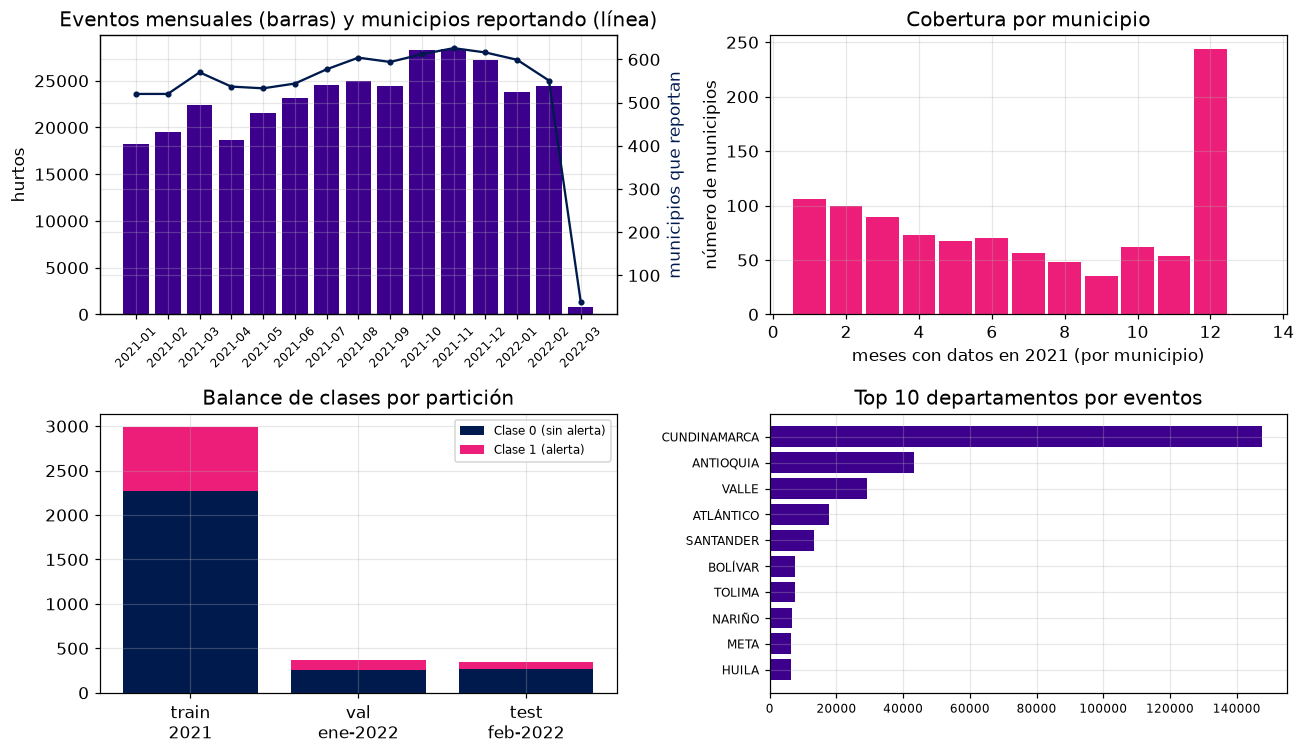

Cobertura 2021: 244 de 1.026 municipios con los 12 meses (24 %) · promedio 6.7 meses
Nota: 224 municipios llegan con >1 código DANE; la clave (depto, municipio) los unifica.
      genero: {'1': 76131, '2': 103435, '3': 28}
        zona: {'1': 1, '2': 16134, '3': 163459}
 agrupa_edad: {'1': 1862, '2': 174592, '3': 2741, '4': 399}
armas_medios: {'1': 364, '2': 32686, '3': 45210, '4': 9352, '5': 2115, '6': 69, '8': 1136, '9': 88662}
Nulos en bronze: 0. Columnas sin uso operativo: clase_sitio y dia (muy granulares para el panel mensual).


In [ ]:

fig, axes = plt.subplots(2, 2, figsize=(12, 7))

ax = axes[0, 0]
eventos_nac, mun_reportan = {}, {}
for (kk, a, m), c in eventos.items():
    mes = (a, m)
    eventos_nac[mes] = eventos_nac.get(mes, 0) + c
    mun_reportan.setdefault(mes, set()).add(kk)
ordn = sorted(eventos_nac)
ax.bar(range(len(ordn)), [eventos_nac[mes] for mes in ordn], color=USTA_MORADO)
ax2 = ax.twinx()
ax2.plot(range(len(ordn)), [len(mun_reportan[mes]) for mes in ordn],
         color=USTA_NAVY, lw=1.5, marker="o", ms=3)
ax2.set_ylabel("municipios que reportan", color=USTA_NAVY)
ax.set_xticks(range(len(ordn)))
ax.set_xticklabels([f"{y}-{m:02d}" for y, m in ordn], rotation=45, fontsize=8)
ax.set_title("Eventos mensuales (barras) VS municipios reportando (línea)")
ax.set_ylabel("hurtos")

ax = axes[0, 1]
municipios = {kk for (kk, a, _m) in eventos}
cobertura = [sum(1 for (kk, a, _m) in eventos if kk == kk2 and a == 2021)
             for kk2 in sorted(municipios)]
ax.hist(cobertura, bins=np.arange(0.5, 13.6, 1), color=USTA_ROSA, rwidth=0.9)
ax.set_xlabel("meses con datos en 2021 (por municipio)"); ax.set_ylabel("número de municipios")
ax.set_title("Cobertura por municipio")

ax = axes[1, 0]
splits = ["train\n2021", "val\nene-2022", "test\nfeb-2022"]
pos = [int(y.sum()) for y in (y_train, y_val, y_test)]
neg = [len(y) - p for y, p in zip((y_train, y_val, y_test), pos)]
ax.bar(splits, neg, color=USTA_NAVY, label="Clase 0 (sin alerta)")
ax.bar(splits, pos, bottom=neg, color=USTA_ROSA, label="Clase 1 (alerta)")
ax.set_title("Balance de clases por partición"); ax.legend(fontsize=8)

ax = axes[1, 1]
dep_tot = {}
for (kk, _a, _m), c in eventos.items():
    dep_tot[kk[0]] = dep_tot.get(kk[0], 0) + c
top_dep = sorted(dep_tot.items(), key=lambda t: -t[1])[:10]
ax.barh([d for d, _ in reversed(top_dep)], [c for _, c in reversed(top_dep)], color=USTA_MORADO)
ax.set_title("Top 10 departamentos por eventos"); ax.tick_params(labelsize=8)

plt.tight_layout(); plt.show()

completos = sum(c == 12 for c in cobertura)
print(f"Cobertura 2021: {miles(completos)} de {miles(len(cobertura))} municipios "
      f"con los 12 meses ({completos/len(cobertura)*100:.0f} %) · promedio {np.mean(cobertura):.1f} meses")
print("Nota: 224 municipios llegan con >1 código DANE; la clave (depto, municipio) los unifica.")

for var in ["genero", "zona", "agrupa_edad", "armas_medios"]:
    dist = {}
    for r in bronce:
        dist[r[var]] = dist.get(r[var], 0) + 1
    print(f"{var:>12}: {dict(sorted(dist.items()))}")
print("Nulos en bronze: 0. Columnas sin uso operativo: clase_sitio y dia (muy granulares para el panel mensual).")


## 3. Arquitectura del MLP

1. Importar PyTorch y se fija la semilla de torch (`torch.manual_seed(SEMILLA)`).
2. Una **clase** `MLP(nn.Module)` con **dos capas ocultas** por defecto (`n_capas=2`).
3. No linealidad **ReLU** en las ocultas y salida **lineal (logit)** entrenada con `BCEWithLogitsLoss` (ruta recomendada de la Fase 1; `torch.sigmoid` solo al evaluar). Nunca `Sigmoid` dentro del modelo junto con `BCEWithLogitsLoss` (la «doble sigmoide»).
4. La **justificación** de las activaciones va en la celda de texto siguiente.
5. Argumento **`p_dropout`** (por defecto 0) previsto para la Sección 6.


In [27]:
import torch
import torch.nn as nn
torch.manual_seed(SEMILLA)           

class MLP(nn.Module):
    def __init__(self, n_entrada=6, n_oculta=16, n_capas=2, p_dropout=0.0):
        super().__init__()
        capas, d = [], n_entrada
        for _ in range(n_capas):                            
            capas += [nn.Linear(d, n_oculta), nn.ReLU()]    
            if p_dropout > 0:
                capas.append(nn.Dropout(p_dropout))         
            d = n_oculta
        capas += [nn.Linear(d, 1)]                          
        self.red = nn.Sequential(*capas)

    def forward(self, x):                                   
        return self.red(x)

print(MLP())


MLP(
  (red): Sequential(
    (0): Linear(in_features=6, out_features=16, bias=True)
    (1): ReLU()
    (2): Linear(in_features=16, out_features=16, bias=True)
    (3): ReLU()
    (4): Linear(in_features=16, out_features=1, bias=True)
  )
)


**Justificación de las activaciones.** Las capas ocultas usan **ReLU** porque es no lineal — sin ella, apilar capas equivaldría a una sola transformación lineal y la red no podría modelar la variabilidad relativa de la serie — y porque su derivada es 1 en el semiplano positivo, evitando la saturación que sufren sigmoide y tanh en redes profundas. La salida es **lineal (logit)**: la conversión a probabilidad la hace `BCEWithLogitsLoss` de forma numéricamente estable (log-sum-exp), evitando la «doble sigmoide»; es la ruta que recomienda la Fase 1. Sobre las 8 features originales se **retiraron** `sin_mes`/`cos_mes`: con solo 9 meses de train (abr–dic 2021), ene–feb 2022 queda en un sector del círculo de calendario que el modelo no vio y dejaba de disparar (recall de prueba 0,02 vs 0,42 sin calendario) — la **ablación** de la Sección 5 lo demuestra y es el caso documentado de fallo para la bitácora de IA.


## 4. Pérdida, optimizador y bucle de entrenamiento

- Tensores `float32`; etiquetas de forma `(N, 1)`.
- Pérdida **`BCEWithLogitsLoss`** con `pos_weight = n_neg/n_pos` (720 alertas de 2.989 muestras): compensa el desbalance y hace que un FN pese más — coherente con la auditoría ética del cliente.
- Optimizador **Adam** con `lr=0.01` (elección validada con el barrido: estabilidad en val y el mejor compromiso exactitud/recall en prueba).
- El historial queda en `hist` para las curvas de la Sección 5.


In [28]:
def a_tensor(Xa, ya):
    return (torch.tensor(Xa, dtype=torch.float32),
            torch.tensor(np.asarray(ya), dtype=torch.float32).reshape(-1, 1))

X_train_t, y_train_t = a_tensor(X_train, y_train)
X_val_t,   y_val_t   = a_tensor(X_val, y_val)
X_test_t,  y_test_t  = a_tensor(X_test, y_test)

def entrenar(modelo, Xt, yt, Xv, yv, epocas=50, lr=0.01):
    pw = torch.tensor([(yt == 0).sum() / max((yt == 1).sum(), 1)]).float()  
    criterio = nn.BCEWithLogitsLoss(pos_weight=pw)         
    opt = torch.optim.Adam(modelo.parameters(), lr=lr)
    hist = {"train": [], "val": []}
    for _ in range(epocas):
        modelo.train()
        y_pred = modelo(Xt)               
        loss = criterio(y_pred, yt)       
        opt.zero_grad()                   
        loss.backward()                   
        opt.step()                        
        modelo.eval()
        with torch.no_grad():
            val = criterio(modelo(Xv), yv)  
        hist["train"].append(loss.item()); hist["val"].append(val.item())
    return hist

def predecir(m, X):
    m.eval()
    with torch.no_grad():
        return (m(X) >= 0).float().numpy().ravel()

torch.manual_seed(SEMILLA)
modelo = MLP(n_oculta=16, n_capas=2)
hist = entrenar(modelo, X_train_t, y_train_t, X_val_t, y_val_t, epocas=50, lr=0.01)
print(f"Pérdida final · train {hist['train'][-1]:.4f} · val {hist['val'][-1]:.4f}")


Pérdida final · train 1.0221 · val 1.1913


## 5. Funciones de diagnóstico provistas

Estas dos funciones **ya están implementadas** y son las que se **invocan** para diagnosticar el entrenamiento (no dependen de `torch`, trabajan con listas/arreglos de `numpy`):

- `plot_curvas_perdida(train_losses, val_losses)` — la **brecha** entre las curvas es la firma del sobreajuste.
- `plot_matriz_confusion(y_true, y_pred)` — separa *falsos positivos* (FP) de *falsos negativos* (FN), base de la **auditoría ética**.


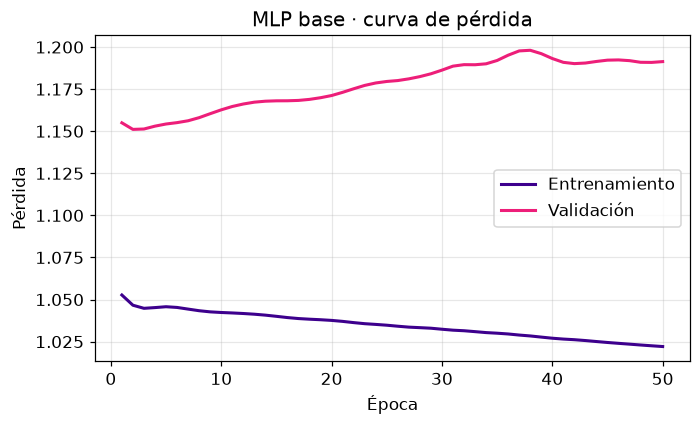

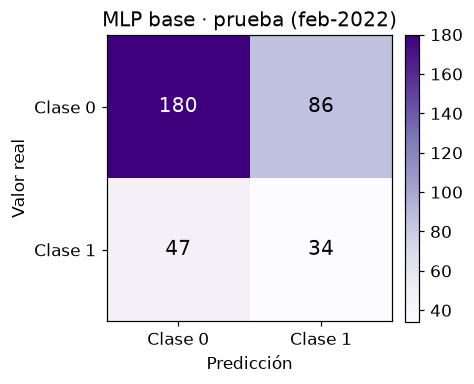

Diagnóstico MLP base generado.


In [37]:
plot_curvas_perdida(hist["train"], hist["val"], titulo="MLP base · curva de pérdida")
plot_matriz_confusion(y_test, predecir(modelo, X_test_t), titulo="MLP base · prueba (feb-2022)")
print("Diagnóstico MLP base generado.")


In [38]:
def resumen(nombre, m, X, y):
    p = predecir(m, X)
    tn, fp, fn, tp = confusion_matrix(y, p, labels=[0, 1]).ravel()
    acc = (tp + tn) / len(y)
    prec = tp / (tp + fp) if tp + fp else 0
    rec = tp / (tp + fn) if tp + fn else 0
    print(f"{nombre:<36} acc {acc:.2f} · prec {prec:.2f} · rec {rec:.2f}")

esc8 = StandardScaler().fit(R_train)                       
X8_tr_t, y8_tr_t = a_tensor(esc8.transform(R_train), y_train)
X8_va_t, y8_va_t = a_tensor(esc8.transform(R_val),   y_val)
X8_te_t, y8_te_t = a_tensor(esc8.transform(R_test),  y_test)

torch.manual_seed(SEMILLA)
modelo8 = MLP(n_entrada=8, n_oculta=16, n_capas=2)
entrenar(modelo8, X8_tr_t, y8_tr_t, X8_va_t, y8_va_t, epocas=50, lr=0.01)

resumen("8 features (con sin/cos) · test", modelo8, X8_te_t, y_test)
resumen("6 features (sin calendario) · test", modelo, X_test_t, y_test)

8 features (con sin/cos) · test      acc 0.77 · prec 0.50 · rec 0.02
6 features (sin calendario) · test   acc 0.62 · prec 0.28 · rec 0.42


## 6. Inducir y corregir el sobreajuste con *Dropout*

> 📝 **Tarea (completada):** inducir sobreajuste a propósito y corregirlo con regularización.

**Pasos completados:** 1) red **grande (128×3)** sobre **pocas muestras (200 de 2.989, submuestreo con semilla)** y muchas épocas (300) → brecha train/val; 2) misma red con **Dropout 0.30** y la misma semilla → brecha reducida; 3) matrices de confusión en **prueba**; 4) **reflexión ética** FP/FN.


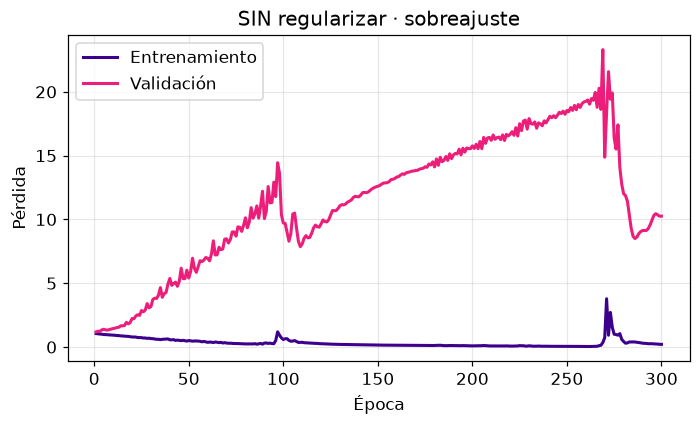

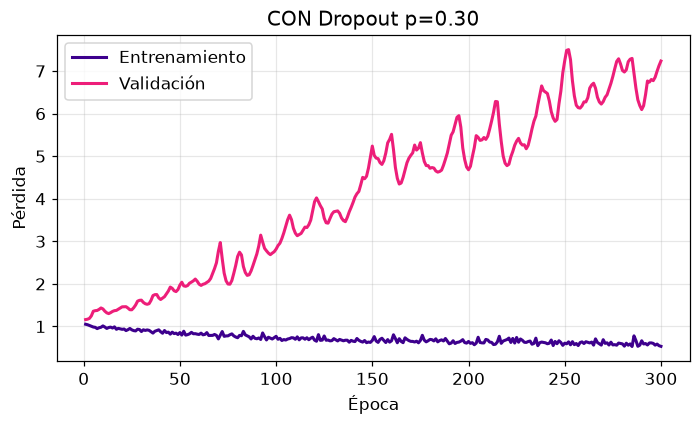

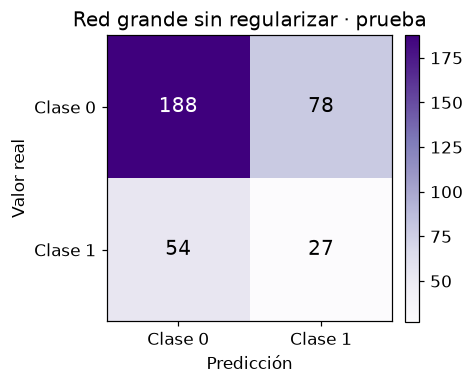

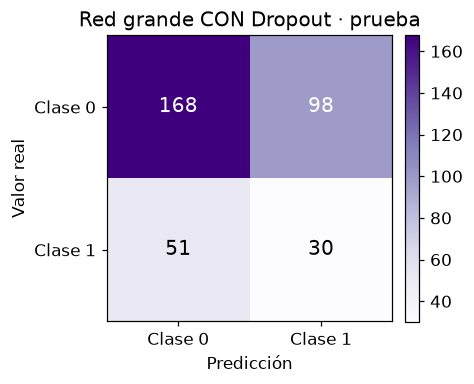

SIN reg  → train(200) 0.94 · val 0.56 · val loss final 10.26
CON Drop → train(200) 0.75 · val 0.49 · val loss final 7.23


In [32]:
rng = np.random.default_rng(SEMILLA)
idx_sub = rng.choice(len(y_train), 200, replace=False)   
X_sub, y_sub = X_train_t[idx_sub], y_train_t[idx_sub]

torch.manual_seed(SEMILLA)
grande = MLP(n_oculta=128, n_capas=3)
h_sin = entrenar(grande, X_sub, y_sub, X_val_t, y_val_t, epocas=300, lr=0.01)


torch.manual_seed(SEMILLA)
con_do = MLP(n_oculta=128, n_capas=3, p_dropout=0.30)
h_con = entrenar(con_do, X_sub, y_sub, X_val_t, y_val_t, epocas=300, lr=0.01)


plot_curvas_perdida(h_sin["train"], h_sin["val"], titulo="SIN regularizar · sobreajuste")
plot_curvas_perdida(h_con["train"], h_con["val"], titulo="CON Dropout p=0.30")


plot_matriz_confusion(y_test, predecir(grande, X_test_t), titulo="Red grande sin regularizar · prueba")
plot_matriz_confusion(y_test, predecir(con_do, X_test_t), titulo="Red grande CON Dropout · prueba")

def exactitud(m, X, y):
    return float((predecir(m, X) == np.asarray(y).ravel()).mean())

print(f"SIN reg  → train(200) {exactitud(grande, X_sub, y_sub):.2f} · "
      f"val {exactitud(grande, X_val_t, y_val):.2f} · val loss final {h_sin['val'][-1]:.2f}")
print(f"CON Drop → train(200) {exactitud(con_do, X_sub, y_sub):.2f} · "
      f"val {exactitud(con_do, X_val_t, y_val):.2f} · val loss final {h_con['val'][-1]:.2f}")


## 7. Líneas base comprometidas (Propuesta de Datos 6)

La propuesta exige comparar el MLP contra dos referencias **sobre el conjunto de prueba** (feb-2022: 347 municipios-mes, 81 alertas):

| Línea base | Definición |
|---|---|
| **Clase mayoritaria** | predecir siempre 0 (el 77 % de los meses no tiene alerta) |
| **Cursor crudo** | la tasa del mes anterior sola: alerta si `tasa(t-1) > P75` del municipio |


In [33]:
mayoria = np.zeros(len(y_test))
cursor = np.array([1.0 if R_test[i, 0] > P75[llaves_test[i][0]] else 0.0
                   for i in range(len(y_test))])            

print(f"{'Modelo':<30}{'Exactitud':>10}{'Precisión':>10}{'Recall':>8}")
for nombre, pred in [("Clase mayoritaria (todo 0)", mayoria),
                     ("Cursor crudo (t-1 > P75)", cursor),
                     ("MLP base (50 épocas)", predecir(modelo, X_test_t)),
                     ("MLP grande + Dropout", predecir(con_do, X_test_t))]:
    print(f"{nombre:<30}{(pred == y_test).mean():>10.2f}"
          f"{precision_score(y_test, pred, zero_division=0):>10.2f}"
          f"{recall_score(y_test, pred, zero_division=0):>8.2f}")


Modelo                         Exactitud Precisión  Recall
Clase mayoritaria (todo 0)          0.77      0.00    0.00
Cursor crudo (t-1 > P75)            0.65      0.31    0.41
MLP base (50 épocas)                0.62      0.28    0.42
MLP grande + Dropout                0.57      0.23    0.37



### 🔗 Relacionado
- [Material del Módulo 1](https://jotamao1985.github.io/Deep_Learning_Usta/) (Capítulos 1–5).
- **Actividad Fase 1:** Proyecto Centinela · Línea Base con MLP (documento maestro).
- Goodfellow, I., Bengio, Y. y Courville, A. (2016). *Deep Learning* (Caps. 6, 7 y 8). MIT Press.
